# TP 2 : Estimateur par projection

In [25]:
import numpy as np
import matplotlib.pyplot as plt

## Exercice 1

1.

In [26]:
X = np.random.uniform(size=100)
epsilon = np.random.normal(0,1,size=100)
sigma = 0.2

def f(x):
    return((x**2*2**(x-1) - (x-0.5)**3)*np.sin(10*x))

Y = f(X) + sigma*epsilon

2.

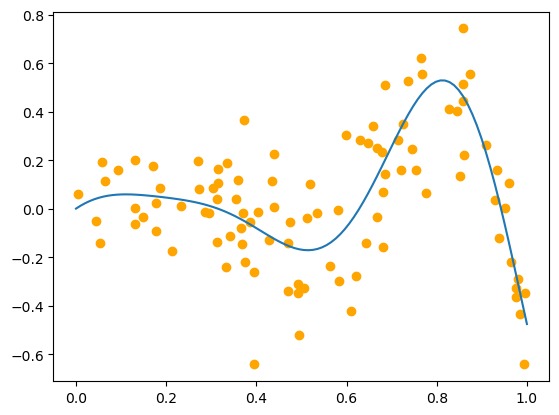

In [27]:
t = np.linspace(0,1,100)
plt.plot(t,f(t))
plt.scatter(X,Y,color='orange')

3.

(a)

In [28]:
def phi(n,x):
    if(n == 1):
        return(np.ones_like(x))
    a = np.sqrt(2)
    if(n % 2 == 0):
        k = n // 2
        return(a*np.cos(2*np.pi*k*x))
    else:
        k = (n+1) // 2
        return(a*np.sin(2*np.pi*k*x))

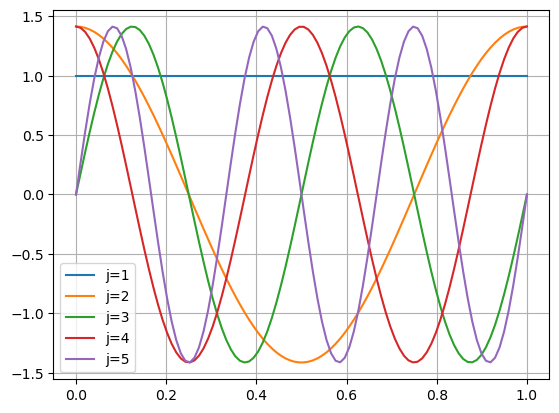

In [29]:
plt.plot(t,phi(1,t),label='j=1')
plt.plot(t,phi(2,t),label='j=2')
plt.plot(t,phi(3,t),label='j=3')
plt.plot(t,phi(4,t),label='j=4')
plt.plot(t,phi(5,t),label='j=5')
plt.grid()
plt.legend()
plt.show()

(b)

In [30]:
def theta_hat(j,X,Y):
   return(np.mean(Y*phi(j,X)))

def f_hat(N,t,X,Y):
    f = 0
    for j in range(1,N+1):
        f += theta_hat(j,X,Y)*phi(j,t)
    return(f)

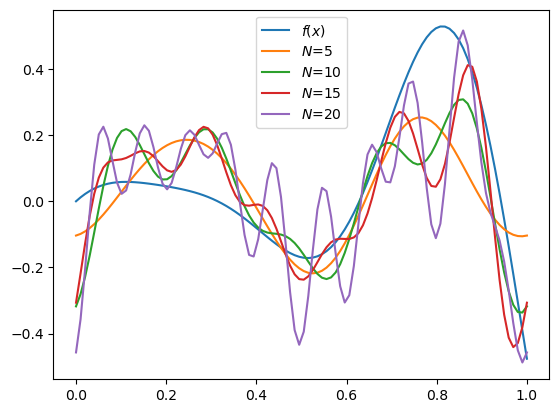

In [31]:
a_list = [5,10,15,20]

plt.plot(t,f(t),label=f'$f(x)$')
for i in a_list:
    plt.plot(t,f_hat(i,t,X,Y),label=f'$N$={i}')
plt.legend()
plt.show()

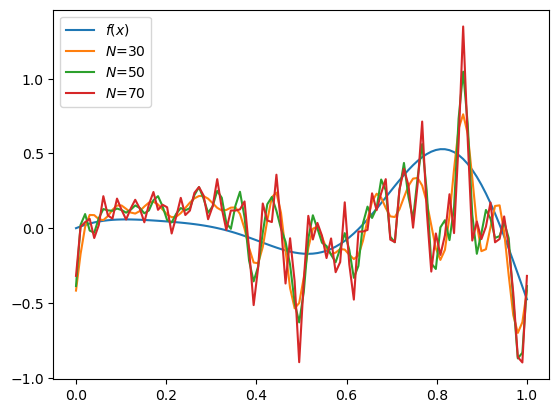

In [32]:
b_list = [30,50,70]

plt.plot(t,f(t),label=f'$f(x)$')
for i in b_list:
    plt.plot(t,f_hat(i,t,X,Y),label=f'$N$={i}')
plt.legend()
plt.show()

(c)

In [33]:
from sklearn.model_selection import KFold

In [34]:
D = np.column_stack((X,Y))
v = 10
kf = KFold(n_splits = v,shuffle=True, random_state=42)
n = len(X)

def quadratic_loss(y_1,y_2):
    return((y_1-y_2)**2)


def error(N,X_test,X_train,Y_train,Y_test):
    e =  np.mean(quadratic_loss(f_hat(N,X_test,X_train,Y_train),Y_test))
    return(e)

N_list = [5,10,15,20,30,50,70]
CV_scores = []
for N in N_list:
    errors = []
    for train_index, test_index in kf.split(D):
        D_train = D[train_index]
        D_test = D[test_index]
        X_train = D_train[:, 0]
        Y_train = D_train[:, 1]
        X_test = D_test[:, 0]
        Y_test = D_test[:, 1]
        e = error(N, X_test, X_train, Y_train, Y_test)
        errors.append(e)
    CV_N = np.mean(errors)
    CV_scores.append(CV_N)

N_opt = N_list[np.argmin(CV_scores)]
print(CV_scores)
print(N_opt)

[0.0579792398042394, 0.057564165031029214, 0.059766701017039604, 0.05987786385959566, 0.06611113388883742, 0.08471700338386372, 0.10351210762137368]
10


4.

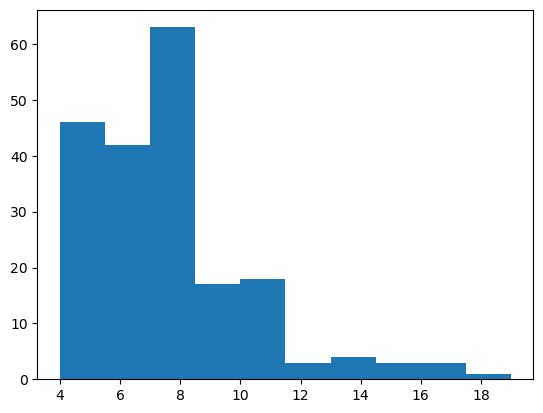

In [38]:
N_list = np.arange(1,21)
N_opt_list = []

for i in range(200):
    X = np.random.uniform(size=100)
    epsilon = np.random.normal(0,1,size=100)
    Y = f(X) + sigma*epsilon
    D = np.column_stack((X,Y))
    CV_scores = []
    
    for N in N_list:
        errors = []
        for train_index, test_index in kf.split(D):
            D_train = D[train_index]
            D_test = D[test_index]
            X_train = D_train[:, 0]
            Y_train = D_train[:, 1]
            X_test = D_test[:, 0]
            Y_test = D_test[:, 1]
            e = error(N, X_test, X_train, Y_train, Y_test)
            errors.append(e)
        CV_N = np.mean(errors)
        CV_scores.append(CV_N)
    
    N_opt = N_list[np.argmin(CV_scores)]
    N_opt_list.append(N_opt)
    
plt.hist(N_opt_list)
plt.show()

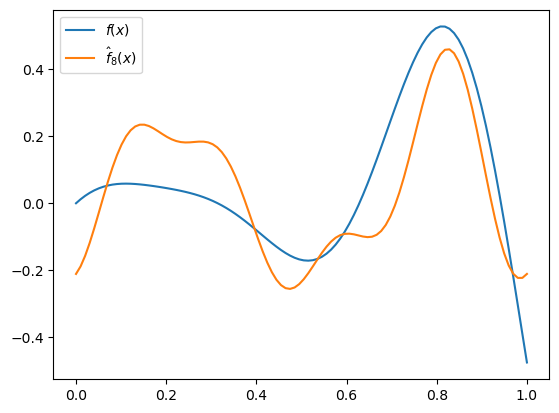

In [45]:
plt.plot(t,f(t),label=f'$f(x)$')
plt.plot(t,f_hat(8,t,X,Y),label=r'$\hat{f}_{8}(x)$')
plt.legend()
plt.show()

## Exercice 2